In [1]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

In [23]:
data = pd.read_csv("RESICE/RESICE_PartA.csv")

ddata = data[~np.isnan(data['depth [m]']) *
    ~np.isnan(data['thickness_sea_ice [m]']) *
    ~np.isnan(data['salinity_sea_ice [ppt]']) *
    ~np.isnan(data['freeboard_sea_ice [m]']) * #note : freeboard measurements only present for 25% of data
    #~np.isnan(data['thickness_snow [m]']) *
    #~np.isnan(data['temperature_air [K]']) *
    #(data['latitude'] > 60) *
    ~np.isnan(data['temperature_sea_ice [K]'])]

idats = ddata[[
    'thickness_sea_ice [m]',
    'depth [m]',
    'temperature_sea_ice [K]',
    'longitude',
    'latitude',
    'salinity_sea_ice [ppt]',
    'freeboard_sea_ice [m]',
    'thickness_snow [m]'
]].copy()

In [24]:
idats

,thickness_sea_ice [m],depth [m],temperature_sea_ice [K],longitude,latitude,salinity_sea_ice [ppt],freeboard_sea_ice [m],thickness_snow [m]
726,1.40,0.20,272.9,-158.15,77.083333,0.0,0.20,0.055
728,1.40,0.30,272.8,-158.15,77.083333,0.2,0.20,0.055
730,1.40,0.40,272.5,-158.15,77.083333,0.9,0.20,0.055
732,1.40,0.50,272.5,-158.15,77.083333,1.5,0.20,0.055
736,1.40,0.70,272.2,-158.15,77.083333,2.1,0.20,0.055
...,...,...,...,...,...,...,...,...
3882,0.81,0.43,267.9,122.58,-65.580000,8.4,0.07,0.010
3883,0.81,0.53,269.1,122.58,-65.580000,6.3,0.07,0.010
3884,0.81,0.63,270.2,122.58,-65.580000,6.8,0.07,0.010
3885,0.81,0.73,270.7,122.58,-65.580000,7.3,0.07,0.010


In [9]:
idats

,thickness_sea_ice [m],depth [m],temperature_sea_ice [K],longitude,salinity_sea_ice [ppt],freeboard_sea_ice [m]
726,1.40,0.20,272.9,-158.15,0.0,0.20
728,1.40,0.30,272.8,-158.15,0.2,0.20
730,1.40,0.40,272.5,-158.15,0.9,0.20
732,1.40,0.50,272.5,-158.15,1.5,0.20
736,1.40,0.70,272.2,-158.15,2.1,0.20
...,...,...,...,...,...,...
3882,0.81,0.43,267.9,122.58,8.4,0.07
3883,0.81,0.53,269.1,122.58,6.3,0.07
3884,0.81,0.63,270.2,122.58,6.8,0.07
3885,0.81,0.73,270.7,122.58,7.3,0.07


In [77]:
from mpl_toolkits.basemap import Basemap

m = Basemap( llcrnrx=-3000000, llcrnry=-3000000, urcrnrx=2000000, urcrnry=3000000, 
             lon_0 = -70, lat_0 = 90, projection="ortho", resolution='l')
#m = Basemap(lon_0 = -70, lat_0 = 90, projection="ortho", resolution='l')
m.drawcoastlines()
parallels = np.arange(0.,90,10.)
m.drawparallels(parallels,labels=[1,0,0,0])
meridians = np.arange(10.,360.,20.)
m.drawmeridians(meridians,labels=[1,0,0,1])

globeplotdata = data[data['date']=='2010-05-05']
m.scatter(globeplotdata['longitude'].values, globeplotdata['latitude'].values, latlon=True)
globeplotdata

aaa


In [87]:
# Translate RESICE data to effective medium dielectric tensors

entries = []
for idc in set(ddata.id):
    stuffs = ddata[ddata.id == idc]
    d, T, S = stuffs['depth [m]'].values, stuffs['temperature_sea_ice [K]'].values - 273.15, stuffs['salinity_sea_ice [ppt]'].values
    entries.append(np.stack((d,T,S), axis=1))

import EffectiveMedium
import PhreeqcSolver

mlen = 0
for entry in entries:
    if (mlen < len(entry)): mlen = len(entry)
seawatr = np.eye(3, dtype=np.complex128) * EffectiveMedium.GW2020_pebrine(T=-1.8, S=35, wavelength=0.229)

icesolver = PhreeqcSolver.frezchem_seawater()
etd_entries = []
ltk_entries = []
for entry in entries:
    stack1, stack2 = [], []
    prev_depth = 0
    i = 0
    for measurement in entry:
        d, T, S = measurement
        etd = EffectiveMedium.solve_bruggeman(T, S, wavelength=0.229, shp_ratio=1.1, ice_solver=icesolver)
        stack1.append(d - prev_depth)
        stack2.append(etd)
        prev_depth = d
        i += 1
    if (len(stack1) < 3): continue # remove entries with just 1 or 2 measurements
    while i < mlen:
        stack1.append(1e-8)
        stack2.append(seawatr)
        i += 1
    ltk_entries.append(stack1)
    etd_entries.append(stack2)

etd, ltk = np.array(etd_entries), np.array(ltk_entries)
np.save('RESICE/looker_etd_cached.npy', etd)
np.save('RESICE/looker_ltk_cached.npy', ltk)
print (etd.shape, ltk.shape)

(113, 33, 3, 3) (113, 33)


In [84]:
import importlib
importlib.reload(EffectiveMedium)
EffectiveMedium.GW2020_pebrine(T=20, S=35, wavelength=0.229)

(72.05718324431571-70.90510041456427j)

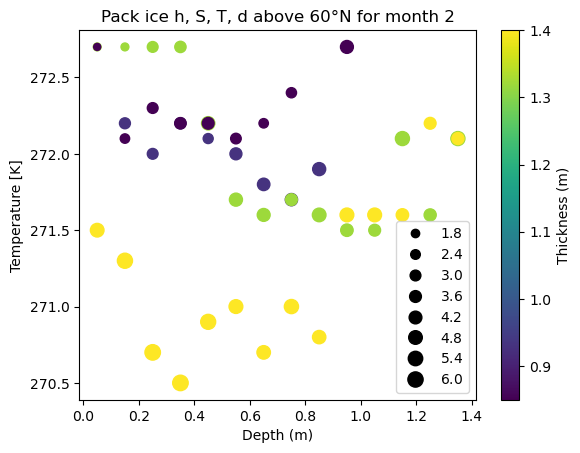

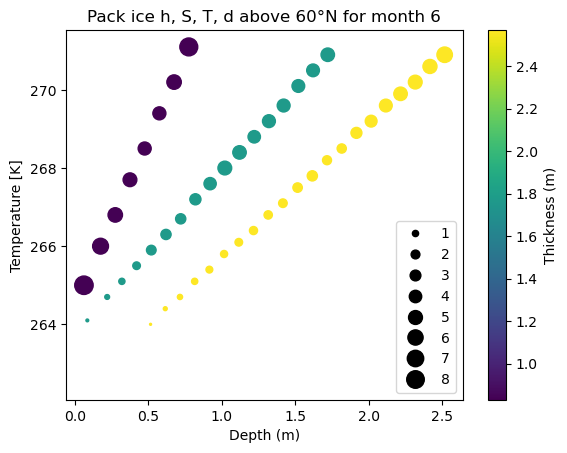

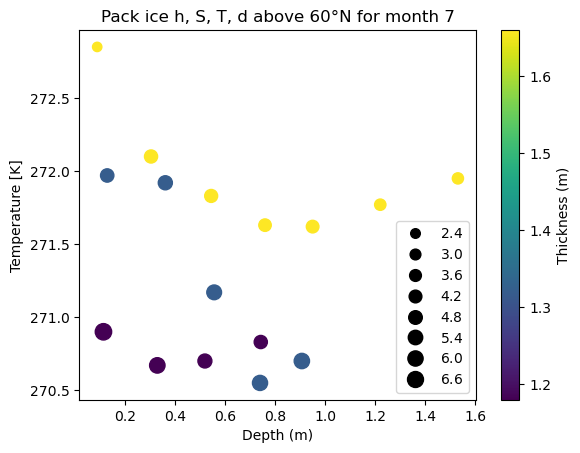

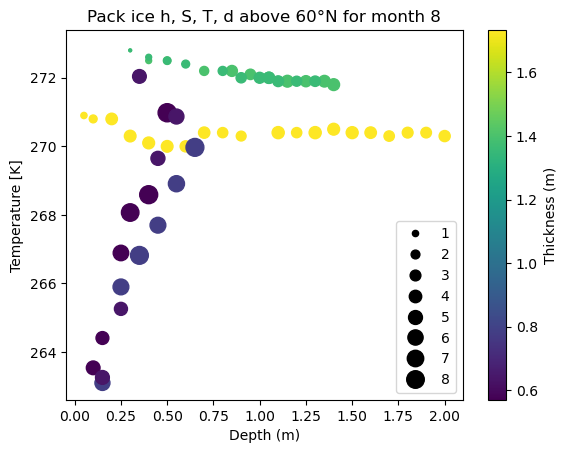

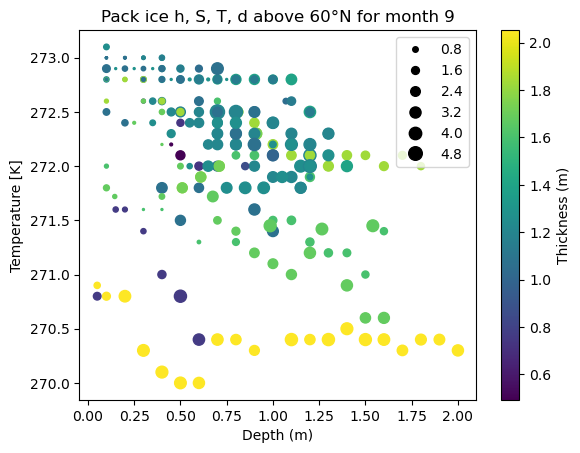

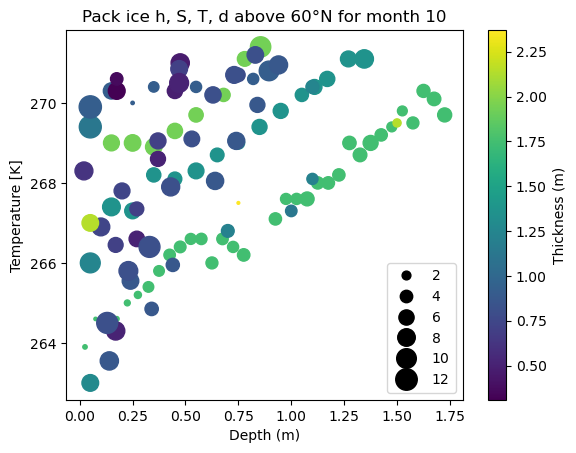

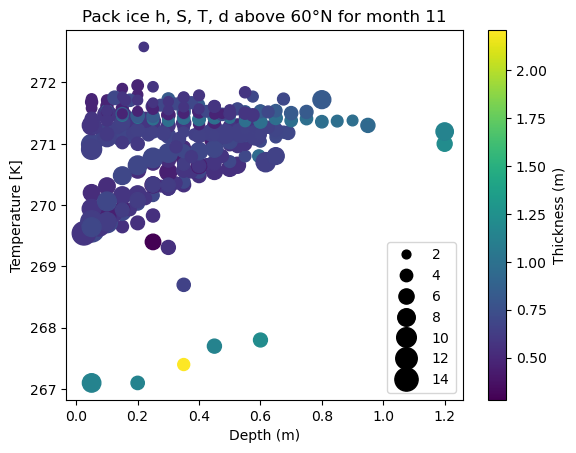

In [19]:

# chartPlots for stuff

for i in range(12):

    ddata = data[~np.isnan(data['depth [m]']) *
        ~np.isnan(data['thickness_sea_ice [m]']) *
        ~np.isnan(data['salinity_sea_ice [ppt]']) *
        #~np.isnan(data['temperature_air [K]']) *
        #(data['latitude'] > 60) *
        ~np.isnan(data['temperature_sea_ice [K]'])]
    
    ddata_pack = ddata[ddata['form_sea_ice'] == 'pack ice']
    ddata_fast = ddata[ddata['form_sea_ice'] == 'fast ice']

    dbase = ddata_pack
    date = np.array([int(el[5:7])*30+int(el[8:10]) for el in dbase['date'].values])
    dbase = dbase[(date - i*30.437 > 0) * (date - i*30.437 < 30.437)]
    if (np.size(dbase) < 1): continue
    
    d,t,s = dbase['depth [m]'].values, dbase['thickness_sea_ice [m]'].values, dbase['salinity_sea_ice [ppt]'].values
    #ak = dbase['temperature_air [K]'].values
    ik = dbase['temperature_sea_ice [K]'].values
    scatter = plt.scatter(d, ik, c=t, s=s*20)
    #scatter = plt.scatter(d, s, c=ik, s=t*20)
    cbar = plt.colorbar()
    cbar.set_label("Thickness (m)")
    plt.title(f"{dbase['form_sea_ice'].iloc[0].capitalize()} h, S, T, d above 60°N for month {i+1}")
    plt.xlabel("Depth (m)")
    plt.ylabel("Temperature [K]")
    
    tmp = plt.legend(*scatter.legend_elements("sizes", num=8, func=(lambda x: x/20)))

    plt.show()
    #print(set(date))
    #fig = plt.figure()
    #ax = fig.add_subplot(projection='3d')
    #mappable = ax.scatter(d,s,date, c=t)
    #fig.colorbar(mappable)

ddata_fast[['2010-05-05' in val for val in ddata_fast['date']]][['salinity_sea_ice [ppt]','depth [m]','temperature_sea_ice [K]']]